<a href="https://colab.research.google.com/github/alancuruz/Brain-Tumor-Classification/blob/main/PCB_Defect_Detection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Check your Colab runtime settings.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q ultralytics opencv-python-headless matplotlib pyyaml

In [3]:
import ultralytics
import cv2

print("Ultralytics version:", ultralytics.__version__)
print("OpenCV version:", cv2.__version__)
print("Environment setup successful!")

Ultralytics version: 8.4.197
OpenCV version: 4.14.0
Environment setup successful!


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

zip_path = "/content/drive/MyDrive/PCB_Defect_Detection/pcb-defect-dataset.zip"

if os.path.exists(zip_path):
    print("SUCCESS: Dataset found!")
    print("File size:",
          round(os.path.getsize(zip_path) / (1024**3), 2),
          "GB")
else:
    print("ERROR: Dataset not found!")

SUCCESS: Dataset found!
File size: 1.1 GB


In [6]:
import os
import zipfile
import shutil

zip_path = "/content/drive/MyDrive/PCB_Defect_Detection/pcb-defect-dataset.zip"
extract_path = "/content/pcb_dataset"

# Check available storage
free_gb = shutil.disk_usage("/content").free / (1024**3)
print("Available Colab storage:", round(free_gb, 2), "GB")

if not os.path.exists(zip_path):
    raise FileNotFoundError("Dataset ZIP file not found!")

# Extract dataset
os.makedirs(extract_path, exist_ok=True)

print("Extracting dataset... Please wait.")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extraction location:", extract_path)

Available Colab storage: 112.52 GB
Extracting dataset... Please wait.
Dataset extracted successfully!
Extraction location: /content/pcb_dataset


In [7]:
import os

dataset_path = "/content/pcb_dataset"

print("PCB DATASET STRUCTURE")
print("=" * 40)

for root, dirs, files in os.walk(dataset_path):

    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        indent = "    " * level

        print(indent + os.path.basename(root) + "/")

        for file in files[:5]:
            print(indent + "    " + file)

PCB DATASET STRUCTURE
pcb_dataset/
    data.yaml
    train/
        images/
            rotation_270_light_09_mouse_bite_10_1_600.jpg
            l_light_08_missing_hole_05_3_600.jpg
            rotation_270_light_05_spur_09_4_600.jpg
            light_10_missing_hole_05_1_600.jpg
            light_08_mouse_bite_06_5_600.jpg
        labels/
            l_light_06_open_circuit_10_1_600.txt
            l_light_11_spur_06_5_600.txt
            rotation_270_light_07_mouse_bite_02_5_600.txt
            rotation_270_light_12_spurious_copper_08_1_600.txt
            rotation_270_light_01_open_circuit_09_3_600.txt
    test/
        images/
            l_light_12_spur_06_4_600.jpg
            light_04_short_03_3_600.jpg
            rotation_270_light_04_spurious_copper_14_2_600.jpg
            rotation_90_light_04_short_16_1_600.jpg
            light_11_spurious_copper_06_3_600.jpg
        labels/
            l_light_05_open_circuit_06_1_600.txt
            light_08_spurious_copper_07_2_256.txt

In [8]:
import yaml

yaml_path = "/content/pcb_dataset/data.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

print("DATASET CONFIGURATION")
print("=====================")

for key, value in data.items():
    print(f"{key}: {value}")

DATASET CONFIGURATION
path: ../pcb-defect-dataset
train: train
val: val
test: test
names: {0: 'mouse_bite', 1: 'spur', 2: 'missing_hole', 3: 'short', 4: 'open_circuit', 5: 'spurious_copper'}


In [9]:
import os

base = "/content/pcb_dataset"

for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    image_names = {os.path.splitext(f)[0] for f in images}
    label_names = {os.path.splitext(f)[0] for f in labels}

    print(f"\n{split.upper()} DATA")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(image_names - label_names))
    print("Labels without images:", len(label_names - image_names))


TRAIN DATA
Images: 8534
Labels: 8534
Images without labels: 2164
Labels without images: 2164

VAL DATA
Images: 1066
Labels: 1066
Images without labels: 264
Labels without images: 264

TEST DATA
Images: 1068
Labels: 1068
Images without labels: 239
Labels without images: 239


In [10]:
import os

label_dir = "/content/pcb_dataset/train/labels"

label_files = [
    f for f in os.listdir(label_dir)
    if f.endswith(".txt")
]

if label_files:
    sample = os.path.join(label_dir, label_files[0])

    print("Sample annotation:", label_files[0])

    with open(sample, "r") as file:
        print(file.read())

Sample annotation: l_light_06_open_circuit_10_1_600.txt
4 0.9533 0.7608 0.0333 0.0283
4 0.6892 0.9700 0.0250 0.0400
4 0.4733 0.2308 0.0333 0.0250



In [11]:
import os
import yaml

base = "/content/pcb_dataset"

# Read dataset configuration
with open(os.path.join(base, "data.yaml"), "r") as f:
    data = yaml.safe_load(f)

print("========== DATASET CONFIGURATION ==========")

print("Number of classes:", data.get("nc"))
print("Class names:", data.get("names"))

print("\n========== DATASET STATISTICS ==========")

for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    image_names = {
        os.path.splitext(f)[0] for f in images
    }

    label_names = {
        os.path.splitext(f)[0] for f in labels
    }

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(image_names - label_names))
    print("Orphan labels:", len(label_names - image_names))

========== DATASET CONFIGURATION ==========
Number of classes: None
Class names: {0: 'mouse_bite', 1: 'spur', 2: 'missing_hole', 3: 'short', 4: 'open_circuit', 5: 'spurious_copper'}

========== DATASET STATISTICS ==========

TRAIN
Images: 8534
Labels: 8534
Missing labels: 2164
Orphan labels: 2164

VAL
Images: 1066
Labels: 1066
Missing labels: 264
Orphan labels: 264

TEST
Images: 1068
Labels: 1068
Missing labels: 239
Orphan labels: 239


In [12]:
import os
import yaml

base = "/content/pcb_dataset"

# 1. Display data.yaml
print("========== DATA.YAML CONTENT ==========")

yaml_path = os.path.join(base, "data.yaml")

with open(yaml_path, "r") as f:
    print(f.read())


# 2. Check images and labels
for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    image_names = {
        os.path.splitext(f)[0] for f in images
    }

    label_names = {
        os.path.splitext(f)[0] for f in labels
    }

    unmatched_images = sorted(image_names - label_names)
    unmatched_labels = sorted(label_names - image_names)

    print(f"\n========== {split.upper()} ==========")

    print("Total images:", len(images))
    print("Total labels:", len(labels))

    print("\nImages without matching labels:")
    print(unmatched_images[:5])

    print("\nLabels without matching images:")
    print(unmatched_labels[:5])

    print("\nFirst 5 image filenames:")
    print(images[:5])

    print("\nFirst 5 label filenames:")
    print(labels[:5])

print("\n========== DIAGNOSTIC COMPLETED ==========")

========== DATA.YAML CONTENT ==========
path: ../pcb-defect-dataset
train: train
val: val
test: test

names:
  0: mouse_bite
  1: spur
  2: missing_hole
  3: short
  4: open_circuit
  5: spurious_copper


========== TRAIN ==========
Total images: 8534
Total labels: 8534

Images without matching labels:
['light_01_missing_hole_01_1_600', 'light_01_missing_hole_01_2_600', 'light_01_missing_hole_02_1_600', 'light_01_missing_hole_03_1_600', 'light_01_missing_hole_04_1_600']

Labels without matching images:
['light_01_missing_hole_01_1_256', 'light_01_missing_hole_01_2_256', 'light_01_missing_hole_02_1_256', 'light_01_missing_hole_03_1_256', 'light_01_missing_hole_04_1_256']

First 5 image filenames:
['rotation_270_light_09_mouse_bite_10_1_600.jpg', 'l_light_08_missing_hole_05_3_600.jpg', 'rotation_270_light_05_spur_09_4_600.jpg', 'light_10_missing_hole_05_1_600.jpg', 'light_08_mouse_bite_06_5_600.jpg']

First 5 label filenames:
['l_light_06_open_circuit_10_1_600.txt', 'l_light_11_spur_06_5

In [13]:
import os

base = "/content/pcb_dataset"

print("========== FILENAME MAPPING CHECK ==========")

total_matched = 0
total_unmatched = 0

for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(".jpg")
    ]

    matched = 0
    unmatched = []

    for image in images:

        image_stem = os.path.splitext(image)[0]

        if image_stem.endswith("_600"):
            label_stem = image_stem[:-4] + "_256"
        else:
            label_stem = image_stem

        label_file = label_stem + ".txt"

        if os.path.exists(os.path.join(label_dir, label_file)):
            matched += 1
        else:
            unmatched.append(image)

    total_matched += matched
    total_unmatched += len(unmatched)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Successfully matched:", matched)
    print("Unmatched:", len(unmatched))

    if unmatched:
        print("Examples:", unmatched[:5])

print("\n========== FINAL SUMMARY ==========")
print("Total matched:", total_matched)
print("Total unmatched:", total_unmatched)

========== FILENAME MAPPING CHECK ==========

TRAIN
Images: 8534
Successfully matched: 2164
Unmatched: 6370
Examples: ['rotation_270_light_09_mouse_bite_10_1_600.jpg', 'l_light_08_missing_hole_05_3_600.jpg', 'rotation_270_light_05_spur_09_4_600.jpg', 'rotation_90_light_07_spurious_copper_06_2_600.jpg', 'l_light_12_missing_hole_05_5_600.jpg']

VAL
Images: 1066
Successfully matched: 264
Unmatched: 802
Examples: ['l_light_11_spurious_copper_03_2_600.jpg', 'rotation_270_light_08_open_circuit_09_4_600.jpg', 'rotation_90_light_04_open_circuit_06_4_600.jpg', 'rotation_270_light_12_mouse_bite_04_3_600.jpg', 'l_light_11_mouse_bite_08_5_600.jpg']

TEST
Images: 1068
Successfully matched: 239
Unmatched: 829
Examples: ['l_light_12_spur_06_4_600.jpg', 'rotation_270_light_04_spurious_copper_14_2_600.jpg', 'rotation_90_light_04_short_16_1_600.jpg', 'l_light_04_missing_hole_13_1_600.jpg', 'rotation_90_light_12_open_circuit_05_1_600.jpg']

========== FINAL SUMMARY ==========
Total matched: 2667
Total un

In [14]:
import os
from collections import Counter

base = "/content/pcb_dataset"

for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.lower().endswith(".txt")
    ]

    print(f"\n========== {split.upper()} ==========")

    print("\nIMAGE filename examples:")
    for name in images[:10]:
        print(name)

    print("\nLABEL filename examples:")
    for name in labels[:10]:
        print(name)

    print("\nIMAGE suffix patterns:")
    print(Counter(name.split("_")[-1] for name in images))

    print("\nLABEL suffix patterns:")
    print(Counter(name.split("_")[-1] for name in labels))


========== TRAIN ==========

IMAGE filename examples:
rotation_270_light_09_mouse_bite_10_1_600
l_light_08_missing_hole_05_3_600
rotation_270_light_05_spur_09_4_600
light_10_missing_hole_05_1_600
light_08_mouse_bite_06_5_600
rotation_90_light_07_spurious_copper_06_2_600
l_light_12_missing_hole_05_5_600
l_light_12_spur_02_4_600
light_04_short_17_2_600
rotation_270_light_06_open_circuit_03_5_600

LABEL filename examples:
l_light_06_open_circuit_10_1_600
l_light_11_spur_06_5_600
rotation_270_light_07_mouse_bite_02_5_600
rotation_270_light_12_spurious_copper_08_1_600
rotation_270_light_01_open_circuit_09_3_600
light_04_mouse_bite_16_1_256
l_light_05_open_circuit_08_4_600
rotation_90_light_06_mouse_bite_04_2_600
light_10_spurious_copper_02_2_256
l_light_04_short_20_4_600

IMAGE suffix patterns:
Counter({'600': 8534})

LABEL suffix patterns:
Counter({'600': 6370, '256': 2164})

========== VAL ==========

IMAGE filename examples:
l_light_11_spurious_copper_03_2_600
rotation_270_light_08_open

In [15]:
import os

base = "/content/pcb_dataset"

total_matched = 0
total_unmatched = 0

for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    exact_matches = 0
    converted_matches = 0
    unmatched = []

    for image in images:

        stem = os.path.splitext(image)[0]

        # First, check for an exact filename match
        exact_label = os.path.join(label_dir, stem + ".txt")

        if os.path.exists(exact_label):
            exact_matches += 1

        else:
            # If exact match fails, try replacing _600 with _256
            if stem.endswith("_600"):
                alternative = stem[:-4] + "_256"
            else:
                alternative = stem

            alternative_label = os.path.join(
                label_dir, alternative + ".txt"
            )

            if os.path.exists(alternative_label):
                converted_matches += 1
            else:
                unmatched.append(image)

    matched = exact_matches + converted_matches

    total_matched += matched
    total_unmatched += len(unmatched)

    print(f"\n========== {split.upper()} ==========")
    print("Total images:", len(images))
    print("Exact matches:", exact_matches)
    print("Converted matches:", converted_matches)
    print("Total matched:", matched)
    print("Unmatched:", len(unmatched))

    if unmatched:
        print("Unmatched examples:", unmatched[:5])

print("\n========== FINAL SUMMARY ==========")
print("Total matched:", total_matched)
print("Total unmatched:", total_unmatched)


========== TRAIN ==========
Total images: 8534
Exact matches: 6370
Converted matches: 2164
Total matched: 8534
Unmatched: 0

========== VAL ==========
Total images: 1066
Exact matches: 802
Converted matches: 264
Total matched: 1066
Unmatched: 0

========== TEST ==========
Total images: 1068
Exact matches: 829
Converted matches: 239
Total matched: 1068
Unmatched: 0

========== FINAL SUMMARY ==========
Total matched: 10668
Total unmatched: 0


In [16]:
import os
import shutil
import yaml

source = "/content/pcb_dataset"
destination = "/content/pcb_dataset_corrected"

splits = ["train", "val", "test"]

# Create corrected dataset
for split in splits:

    image_source = os.path.join(source, split, "images")
    label_source = os.path.join(source, split, "labels")

    image_destination = os.path.join(destination, split, "images")
    label_destination = os.path.join(destination, split, "labels")

    os.makedirs(image_destination, exist_ok=True)
    os.makedirs(label_destination, exist_ok=True)

    images = [
        f for f in os.listdir(image_source)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image in images:

        image_stem = os.path.splitext(image)[0]

        # Copy image
        shutil.copy2(
            os.path.join(image_source, image),
            os.path.join(image_destination, image)
        )

        # Find corresponding label
        exact_label = image_stem + ".txt"

        if os.path.exists(os.path.join(label_source, exact_label)):
            label_file = exact_label

        else:
            label_stem = image_stem[:-4] + "_256"
            label_file = label_stem + ".txt"

        # Copy label using the image's filename
        shutil.copy2(
            os.path.join(label_source, label_file),
            os.path.join(label_destination, image_stem + ".txt")
        )

    print(f"{split.upper()} dataset prepared successfully!")

# Create corrected YAML configuration
data_config = {
    "path": destination,
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": 6,
    "names": {
        0: "mouse_bite",
        1: "spur",
        2: "missing_hole",
        3: "short",
        4: "open_circuit",
        5: "spurious_copper"
    }
}

yaml_path = os.path.join(destination, "data.yaml")

with open(yaml_path, "w") as file:
    yaml.dump(data_config, file, sort_keys=False)

print("\nCorrected dataset created successfully!")
print("Configuration:", yaml_path)

TRAIN dataset prepared successfully!
VAL dataset prepared successfully!
TEST dataset prepared successfully!

Corrected dataset created successfully!
Configuration: /content/pcb_dataset_corrected/data.yaml


In [17]:
import os

base = "/content/pcb_dataset_corrected"

for split in ["train", "val", "test"]:

    image_dir = os.path.join(base, split, "images")
    label_dir = os.path.join(base, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Counts match:", len(images) == len(labels))


TRAIN
Images: 8534
Labels: 8534
Counts match: True

VAL
Images: 1066
Labels: 1066
Counts match: True

TEST
Images: 1068
Labels: 1068
Counts match: True


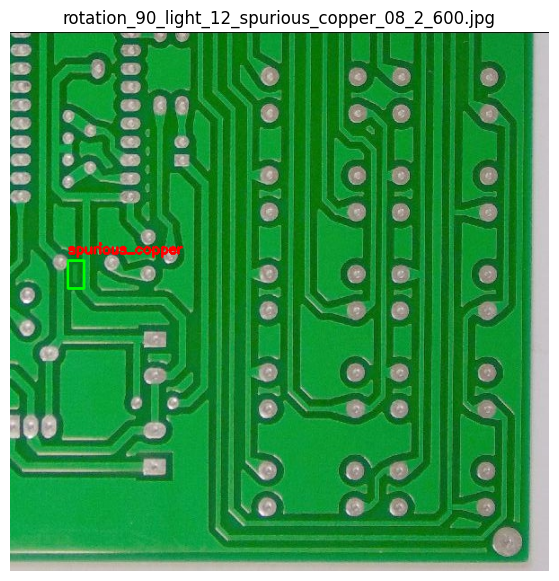

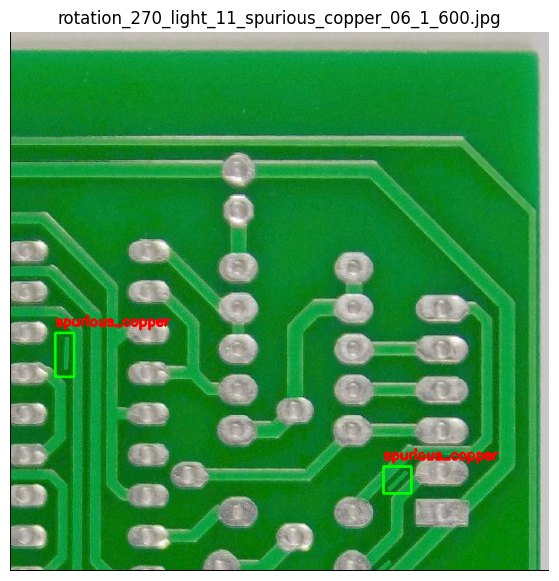

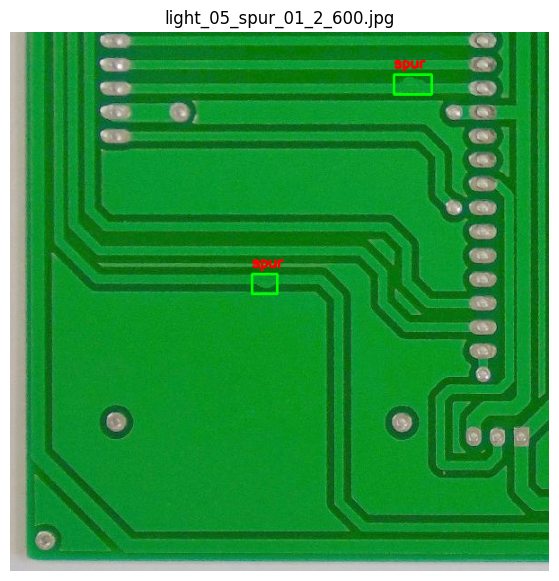

In [18]:
import os
import cv2
import random
import matplotlib.pyplot as plt

base = "/content/pcb_dataset_corrected"

class_names = [
    "mouse_bite",
    "spur",
    "missing_hole",
    "short",
    "open_circuit",
    "spurious_copper"
]

image_dir = os.path.join(base, "train/images")
label_dir = os.path.join(base, "train/labels")

images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

samples = random.sample(images, 3)

for image_name in samples:

    image_path = os.path.join(image_dir, image_name)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(image_name)[0] + ".txt"
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width, _ = image.shape

    with open(label_path, "r") as file:

        for line in file:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id, x_center, y_center, box_width, box_height = map(
                float, values
            )

            x_center *= width
            y_center *= height
            box_width *= width
            box_height *= height

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            label = class_names[int(class_id)]

            cv2.putText(
                image,
                label,
                (x1, max(y1 - 8, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")
    plt.show()

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [22]:
from ultralytics import YOLO

# Load pretrained YOLO11 Nano
model = YOLO("yolo11n.pt")

# Start optimized training
results = model.train(
    data="/content/pcb_dataset_corrected/data.yaml",
    epochs=15,
    imgsz=416,
    batch=16,
    patience=5,
    device=0,
    workers=2,
    project="/content/drive/MyDrive/PCB_Project",
    name="PCB_YOLO_Training",
    save=True,
    save_period=1,
    exist_ok=True
)

print("Training completed successfully!")

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pcb_dataset_corrected/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=PCB_YOLO_Training, nbs=64, nms=None, opset=None, 

In [23]:
import os

weights_path = "/content/drive/MyDrive/PCB_Project/PCB_YOLO_Training/weights"

print("Checking trained model files...\n")

if os.path.exists(weights_path):

    for file in os.listdir(weights_path):
        print("Found:", file)

    best_model = os.path.join(weights_path, "best.pt")
    last_model = os.path.join(weights_path, "last.pt")

    print("\nBest model exists:", os.path.exists(best_model))
    print("Latest checkpoint exists:", os.path.exists(last_model))

else:
    print("Training weights folder not found.")

Checking trained model files...

Found: last.pt
Found: best.pt
Found: epoch0.pt
Found: epoch1.pt
Found: epoch2.pt
Found: epoch3.pt
Found: epoch4.pt
Found: epoch5.pt
Found: epoch6.pt
Found: epoch7.pt
Found: epoch8.pt
Found: epoch9.pt
Found: epoch10.pt
Found: epoch11.pt
Found: epoch12.pt
Found: epoch13.pt
Found: epoch14.pt

Best model exists: True
Latest checkpoint exists: True


In [24]:
from ultralytics import YOLO

# Load the best trained model
model = YOLO(
    "/content/drive/MyDrive/PCB_Project/PCB_YOLO_Training/weights/best.pt"
)

# Evaluate using the test dataset
results = model.val(
    data="/content/pcb_dataset_corrected/data.yaml",
    split="test",
    imgsz=416,
    batch=16,
    device=0
)

# Display evaluation metrics
print("\n========== PCB DEFECT DETECTION RESULTS ==========")

print("Precision:", round(results.box.mp, 4))
print("Recall:", round(results.box.mr, 4))
print("mAP50:", round(results.box.map50, 4))
print("mAP50-95:", round(results.box.map, 4))

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2300.5±1020.8 MB/s, size: 93.9 KB)
val: Scanning /content/pcb_dataset_corrected/test/labels... 1068 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1068/1068 1.9Kit/s 0.5s
val: New cache created: /content/pcb_dataset_corrected/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 6.2it/s 10.8s
                   all       1068       2158      0.973      0.953      0.975      0.513
            mouse_bite        168        332      0.955      0.937      0.967        0.5
                  spur        169        348      0.979      0.918      0.968      0.501
          missing_hole        190        379      0.989      0.995      0.993      0.554
                 short        184        366      

In [25]:
from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Image

# Load trained model
model = YOLO(
    "/content/drive/MyDrive/PCB_Project/PCB_YOLO_Training/weights/best.pt"
)

# Upload a PCB image
uploaded = files.upload()

# Get uploaded image path
image_path = next(iter(uploaded.keys()))

# Perform defect detection
results = model.predict(
    source=image_path,
    imgsz=416,
    conf=0.25,
    save=True
)

# Display detection result
result_path = results[0].save_dir / (
    results[0].path.split("/")[-1]
)

display(Image(filename=str(result_path)))

StopIteration: 

In [26]:
from ultralytics import YOLO
import os
from IPython.display import display, Image

model = YOLO(
    "/content/drive/MyDrive/PCB_Project/PCB_YOLO_Training/weights/best.pt"
)

test_dir = "/content/pcb_dataset_corrected/test/images"

image_name = os.listdir(test_dir)[0]
image_path = os.path.join(test_dir, image_name)

results = model.predict(
    source=image_path,
    imgsz=416,
    conf=0.25,
    save=True
)

result_path = results[0].save_dir / image_name

display(Image(filename=str(result_path)))


image 1/1 /content/pcb_dataset_corrected/test/images/l_light_12_spur_06_4_600.jpg: 416x416 4 spurs, 7.7ms
Speed: 2.6ms preprocess, 7.7ms inference, 1.6ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict


TypeError: unsupported operand type(s) for /: 'str' and 'str'

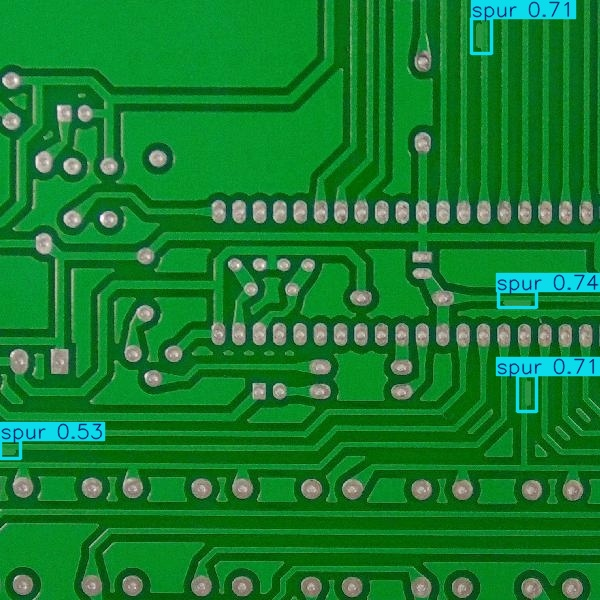

In [27]:
from IPython.display import display, Image
import os

# Get the saved detection image path
result_path = os.path.join(
    str(results[0].save_dir),
    os.path.basename(results[0].path)
)

# Display the result
display(Image(filename=result_path))